In [3]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import IsolationForest
from sklearn.metrics import classification_report, confusion_matrix



In [4]:

# Load the dataset
data = pd.read_csv("../data/creditcard.csv")

# Display  dataset information
print("Dataset shape:", data.shape)
display(data.head())


Dataset shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [5]:

# Inspect dataset structure and data types
data.info()


<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [6]:

# Check for missing values
print(data.isnull().sum())


Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64


In [7]:

# Generate descriptive statistics
display(data.describe())


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,...,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


Class
0    284315
1       492
Name: count, dtype: int64


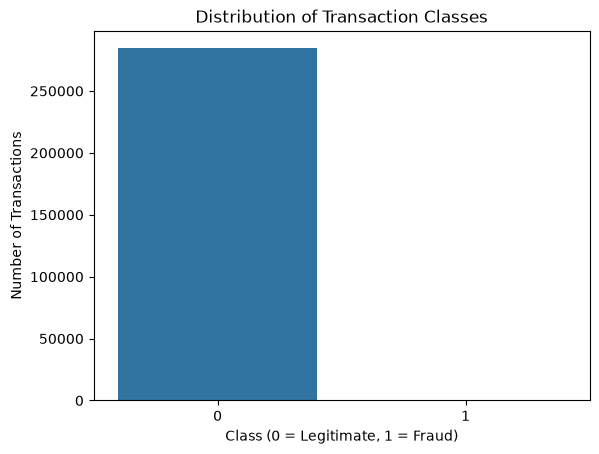

In [8]:

# Examine the distribution of transaction classes
print(data["Class"].value_counts())

# Visualize the class distribution
sns.countplot(data=data, x="Class")
plt.title("Distribution of Transaction Classes")
plt.xlabel("Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Number of Transactions")
plt.show()


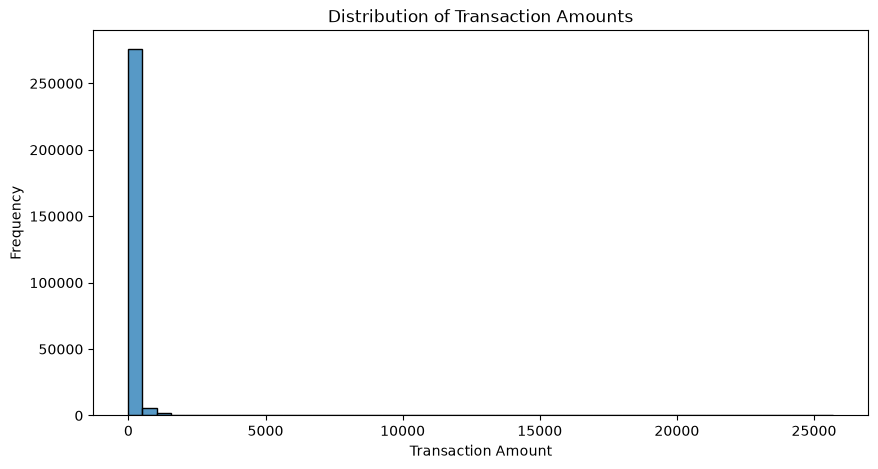

In [9]:

# Visualize transaction amount distribution
plt.figure(figsize=(10, 5))
sns.histplot(data["Amount"], bins=50)
plt.title("Distribution of Transaction Amounts")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")
plt.show()


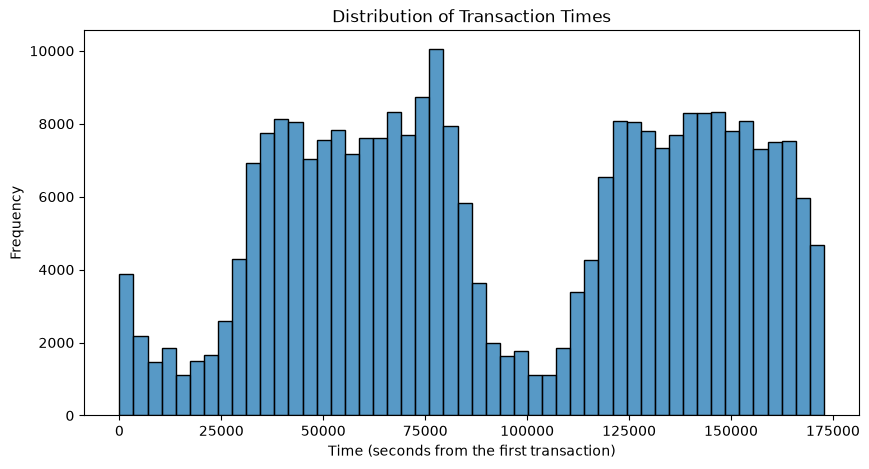

In [10]:

# Visualize transaction time distribution
plt.figure(figsize=(10, 5))
sns.histplot(data["Time"], bins=50)
plt.title("Distribution of Transaction Times")
plt.xlabel("Time (seconds from the first transaction)")
plt.ylabel("Frequency")
plt.show()


In [11]:

# Separate transaction features from the labels used for evaluation
X = data.drop(columns=["Class"])
y = data["Class"]

# Display the shapes of the features and labels
print("Features shape:", X.shape)
print("Labels shape:", y.shape)


Features shape: (284807, 30)
Labels shape: (284807,)


In [12]:

# Scale the transaction features
scaler = MinMaxScaler()
X_scaled = pd.DataFrame(
    scaler.fit_transform(X),
    columns=X.columns
)

# Display the scaled features
display(X_scaled.head())


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount
0,0.000000,0.935192,0.766490,0.881365,0.313023,0.763439,0.267669,0.266815,0.786444,0.475312,...,0.582942,0.561184,0.522992,0.663793,0.391253,0.585122,0.394557,0.418976,0.312697,0.005824
1,0.000000,0.978542,0.770067,0.840298,0.271796,0.766120,0.262192,0.264875,0.786298,0.453981,...,0.579530,0.557840,0.480237,0.666938,0.336440,0.587290,0.446013,0.416345,0.313423,0.000105
2,0.000006,0.935217,0.753118,0.868141,0.268766,0.762329,0.281122,0.270177,0.788042,0.410603,...,0.585855,0.565477,0.546030,0.678939,0.289354,0.559515,0.402727,0.415489,0.311911,0.014739
3,0.000006,0.941878,0.765304,0.868484,0.213661,0.765647,0.275559,0.266803,0.789434,0.414999,...,0.578050,0.559734,0.510277,0.662607,0.223826,0.614245,0.389197,0.417669,0.314371,0.004807
4,0.000012,0.938617,0.776520,0.864251,0.269796,0.762975,0.263984,0.268968,0.782484,0.490950,...,0.584615,0.561327,0.547271,0.663392,0.401270,0.566343,0.507497,0.420561,0.317490,0.002724


In [13]:

# Verify the scaled feature ranges
print("Minimum scaled value:", X_scaled.min().min())
print("Maximum scaled value:", X_scaled.max().max())

# Check for missing values after scaling
print("Missing values:", X_scaled.isnull().sum().sum())


Minimum scaled value: 0.0
Maximum scaled value: 1.0
Missing values: 0


In [14]:

# Split the data into training and testing sets
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Scale features using the training data only
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train the Isolation Forest model without fraud labels
model = IsolationForest(
    n_estimators=100,
    contamination="auto",
    random_state=42
)

model.fit(X_train_scaled)

# Display the training and testing sizes
print("Training samples:", X_train_scaled.shape[0])
print("Testing samples:", X_test_scaled.shape[0])
print("Model trained successfully!")


Training samples: 227845
Testing samples: 56962
Model trained successfully!


In [15]:

# Predict anomalies in the test data
predictions = model.predict(X_test_scaled)

# Convert predictions to fraud and normal labels
y_pred = np.where(predictions == -1, 1, 0)

# Display the number of detected anomalies
print("Detected anomalies:", np.sum(y_pred == 1))
print("Predicted normal transactions:", np.sum(y_pred == 0))


Detected anomalies: 1968
Predicted normal transactions: 54994


In [16]:

# Evaluate anomaly detection performance
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Legitimate", "Fraud"],
    zero_division=0
))


Confusion Matrix:
[[54979  1885]
 [   15    83]]

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      0.97      0.98     56864
       Fraud       0.04      0.85      0.08        98

    accuracy                           0.97     56962
   macro avg       0.52      0.91      0.53     56962
weighted avg       1.00      0.97      0.98     56962



In [17]:

# Combine test features with actual labels and model predictions
results = X_test.copy()
results["Actual_Class"] = y_test
results["Predicted_Anomaly"] = y_pred

# Display detected anomalies
anomalies = results[results["Predicted_Anomaly"] == 1]
display(anomalies.head())

# Summarize the predictions
print("Total transactions evaluated:", len(results))
print("Total anomalies detected:", len(anomalies))
print("Actual fraud cases detected:", anomalies["Actual_Class"].sum())


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V22,V23,V24,V25,V26,V27,V28,Amount,Actual_Class,Predicted_Anomaly
147283,88326.0,-3.576495,2.318422,1.306985,3.263665,1.127818,2.865246,1.444125,-0.718922,1.874046,...,0.016867,-0.132058,-1.483996,-0.296011,0.062823,0.552411,0.509764,76.07,0,1
83371,59813.0,-3.502600,2.730569,-0.962733,1.496190,-7.251700,6.702511,0.643728,-10.519864,-1.660539,...,1.876467,0.478593,0.084482,-0.027255,-0.240761,1.150424,-0.291471,1222.48,0,1
222756,143104.0,-2.481916,-0.019879,0.776380,-2.039680,-2.211452,1.018885,1.072739,-3.873131,-0.296687,...,-1.826313,-0.965027,0.096806,0.316642,-0.485333,1.048360,-0.424243,598.75,0,1
94688,64988.0,-7.585367,4.630271,-1.798507,0.942801,-3.245619,0.596111,-2.219822,2.507796,3.406173,...,-0.745756,0.506285,0.117246,0.192770,-0.591036,-1.253796,0.826483,13.74,0,1
190263,128759.0,-1.272117,1.827615,-3.810610,0.583759,-0.641242,-1.389043,-1.954054,1.173920,-2.053191,...,0.858775,0.083079,0.741676,-0.173234,0.534870,0.183562,0.020316,0.76,0,1


Total transactions evaluated: 56962
Total anomalies detected: 1968
Actual fraud cases detected: 83


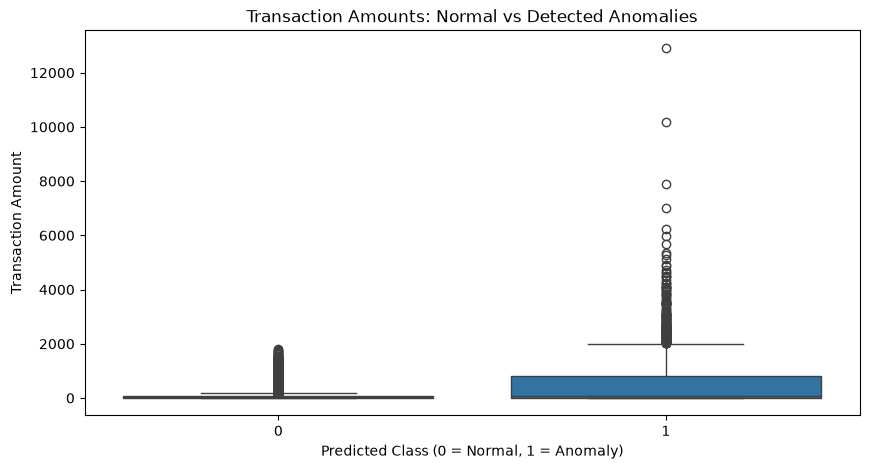

In [18]:

# Compare transaction amounts across actual and predicted classes
plt.figure(figsize=(10, 5))
sns.boxplot(data=results, x="Predicted_Anomaly", y="Amount")
plt.title("Transaction Amounts: Normal vs Detected Anomalies")
plt.xlabel("Predicted Class (0 = Normal, 1 = Anomaly)")
plt.ylabel("Transaction Amount")
plt.show()


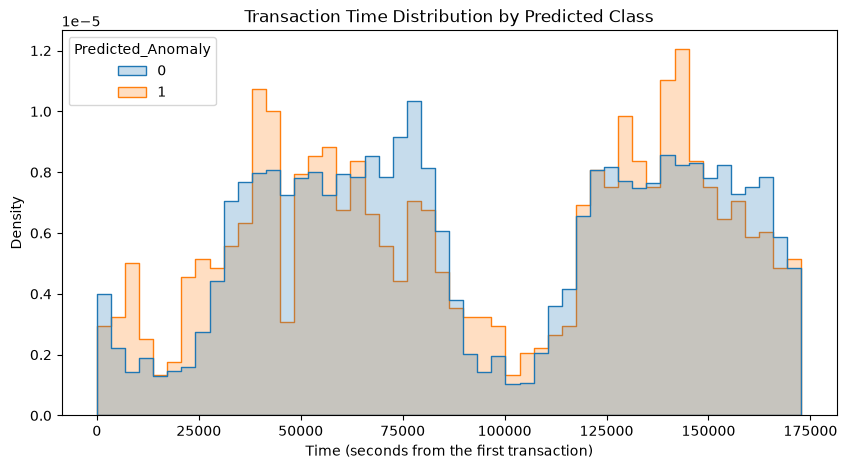

In [19]:

# Compare transaction times across predicted classes
plt.figure(figsize=(10, 5))
sns.histplot(
    data=results,
    x="Time",
    hue="Predicted_Anomaly",
    bins=50,
    element="step",
    stat="density",
    common_norm=False
)
plt.title("Transaction Time Distribution by Predicted Class")
plt.xlabel("Time (seconds from the first transaction)")
plt.ylabel("Density")
plt.show()


In [20]:

# Compare transaction statistics by predicted class
summary = results.groupby("Predicted_Anomaly")[["Amount", "Time"]].agg(
    ["mean", "median", "count"]
)

display(summary)


Amount                         Time                
                         mean  median  count          mean   median  count
Predicted_Anomaly                                                         
0                   71.932652  21.255  54994  94586.496272  84421.5  54994
1                  567.173364  88.480   1968  92920.199695  87874.5   1968

In [21]:

# Split the data into training, validation, and test sets
from sklearn.model_selection import train_test_split

X_train_val, X_test_final, y_train_val, y_test_final = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

X_train_final, X_val, y_train_final, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.25,
    random_state=42,
    stratify=y_train_val
)

# Scale features using training data only
scaler_final = MinMaxScaler()
X_train_final_scaled = scaler_final.fit_transform(X_train_final)
X_val_scaled = scaler_final.transform(X_val)
X_test_final_scaled = scaler_final.transform(X_test_final)

# Display split sizes
print("Training samples:", len(X_train_final))
print("Validation samples:", len(X_val))
print("Test samples:", len(X_test_final))


Training samples: 170883
Validation samples: 56962
Test samples: 56962


In [22]:

# Compare Isolation Forest contamination settings
from sklearn.metrics import precision_score, recall_score, f1_score

contamination_values = [0.005, 0.01, 0.02]
comparison_results = []

for contamination in contamination_values:
    model = IsolationForest(
        n_estimators=100,
        contamination=contamination,
        random_state=42,
        n_jobs=-1
    )

    # Train without fraud labels
    model.fit(X_train_final_scaled)

    # Predict anomalies on validation data
    val_predictions = model.predict(X_val_scaled)
    val_predictions = np.where(val_predictions == -1, 1, 0)

    # Evaluate predictions using validation labels
    comparison_results.append({
        "Contamination": contamination,
        "Precision": precision_score(y_val, val_predictions, zero_division=0),
        "Recall": recall_score(y_val, val_predictions, zero_division=0),
        "F1-Score": f1_score(y_val, val_predictions, zero_division=0),
        "Detected Anomalies": int(val_predictions.sum())
    })

# Display model comparison
comparison_df = pd.DataFrame(comparison_results)
display(comparison_df)


,Contamination,Precision,Recall,F1-Score,Detected Anomalies
0,0.005,0.122112,0.373737,0.184080,303
1,0.010,0.088496,0.505051,0.150602,565
2,0.020,0.059397,0.676768,0.109209,1128


In [23]:

# Train the selected Isolation Forest model
best_model = IsolationForest(
    n_estimators=100,
    contamination=0.005,
    random_state=42,
    n_jobs=-1
)

best_model.fit(X_train_final_scaled)

# Predict anomalies on the test set
test_predictions = best_model.predict(X_test_final_scaled)
y_test_pred = np.where(test_predictions == -1, 1, 0)

# Evaluate the final model
print("Confusion Matrix:")
print(confusion_matrix(y_test_final, y_test_pred))

print("\nClassification Report:")
print(classification_report(
    y_test_final,
    y_test_pred,
    target_names=["Legitimate", "Fraud"],
    zero_division=0
))


Confusion Matrix:
[[56605   259]
 [   55    43]]

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56864
       Fraud       0.14      0.44      0.21        98

    accuracy                           0.99     56962
   macro avg       0.57      0.72      0.61     56962
weighted avg       1.00      0.99      1.00     56962



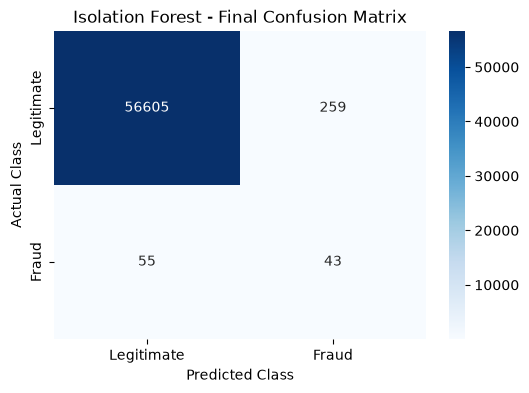

In [24]:

# Visualize the final model's confusion matrix
cm = confusion_matrix(y_test_final, y_test_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraud"],
    yticklabels=["Legitimate", "Fraud"]
)

plt.title("Isolation Forest - Final Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()


In [25]:

# Calculate final evaluation metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

final_metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Fraud Precision", "Fraud Recall", "Fraud F1-Score"],
    "Score": [
        accuracy_score(y_test_final, y_test_pred),
        precision_score(y_test_final, y_test_pred, zero_division=0),
        recall_score(y_test_final, y_test_pred, zero_division=0),
        f1_score(y_test_final, y_test_pred, zero_division=0)
    ]
})

# Display the final evaluation results
display(final_metrics.round(4))


,Metric,Score
0,Accuracy,0.9945
1,Fraud Precision,0.1424
2,Fraud Recall,0.4388
3,Fraud F1-Score,0.2150


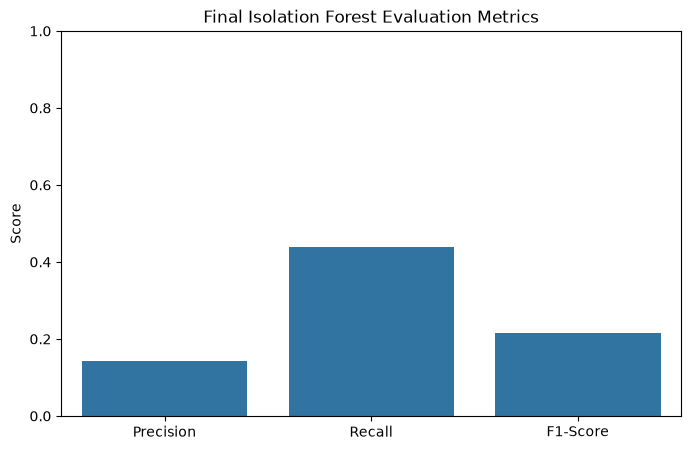

Precision: 0.1424
Recall: 0.4388
F1-Score: 0.2150


In [26]:

# Calculate and visualize final evaluation metrics
from sklearn.metrics import precision_score, recall_score, f1_score

metrics = {
    "Precision": precision_score(y_test_final, y_test_pred, zero_division=0),
    "Recall": recall_score(y_test_final, y_test_pred, zero_division=0),
    "F1-Score": f1_score(y_test_final, y_test_pred, zero_division=0)
}

plt.figure(figsize=(8, 5))
sns.barplot(x=list(metrics.keys()), y=list(metrics.values()))
plt.ylim(0, 1)
plt.title("Final Isolation Forest Evaluation Metrics")
plt.ylabel("Score")
plt.show()

# Display metric values
for name, score in metrics.items():
    print(f"{name}: {score:.4f}")


In [27]:

# Compare average feature values for normal and anomalous transactions
feature_comparison = X_test_final.copy()
feature_comparison["Predicted_Anomaly"] = y_test_pred

feature_means = feature_comparison.groupby("Predicted_Anomaly").mean().T
feature_means.columns = ["Normal", "Anomaly"]

feature_means["Absolute_Difference"] = abs(
    feature_means["Anomaly"] - feature_means["Normal"]
)

# Display features with the largest differences
display(
    feature_means.sort_values(
        "Absolute_Difference",
        ascending=False
    ).head(10)
)


,Normal,Anomaly,Absolute_Difference
Time,94573.296664,86204.437086,8368.859578
Amount,83.156647,1193.396854,1110.240207
V1,0.052216,-10.396600,10.448816
V3,0.034165,-6.120926,6.155091
V5,0.020164,-3.914830,3.934995
V2,0.019331,-3.263990,3.283321
V4,-0.013977,2.637121,2.651098
V17,0.008797,-1.944881,1.953678
V8,0.011895,-1.904374,1.916269
V7,0.007633,-1.489918,1.497550
